In [15]:
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.datasets import load_iris

In [3]:
# load in the log file
df = pd.read_csv('logs.csv')
label_encoder = LabelEncoder()

# you can change/reduce the number of features
cols = ['eventTime', 'readOnly', 'eventCategory', 'eventName', 'eventSource', 'sourceIPAddress', 'errorMessage', 'errorCode', 'eventType', 'attack']
# df = df.drop(columns=['readOnly','eventCategory','eventName','eventSource','eventType'])

# this labels the data as categorical (except eventTime)
for j in df.columns[1:]:
    df[j] = df[j].astype('category')
    encoded_numbers = label_encoder.fit_transform(df[j])
    df[j] = encoded_numbers


In [4]:
X = df.iloc[:, :-2].values
y = df.iloc[:,-1:].values
y = y.flatten()

# splits the dataset into train/test at 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=40)

In [19]:
# comment in/out the classifer you want to test

#classifier = RandomForestClassifier(n_estimators=100, random_state=42)
#classifier = KNeighborsClassifier()
classifier = SVC(kernel='linear', C=1.0, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

Accuracy: 97.16%


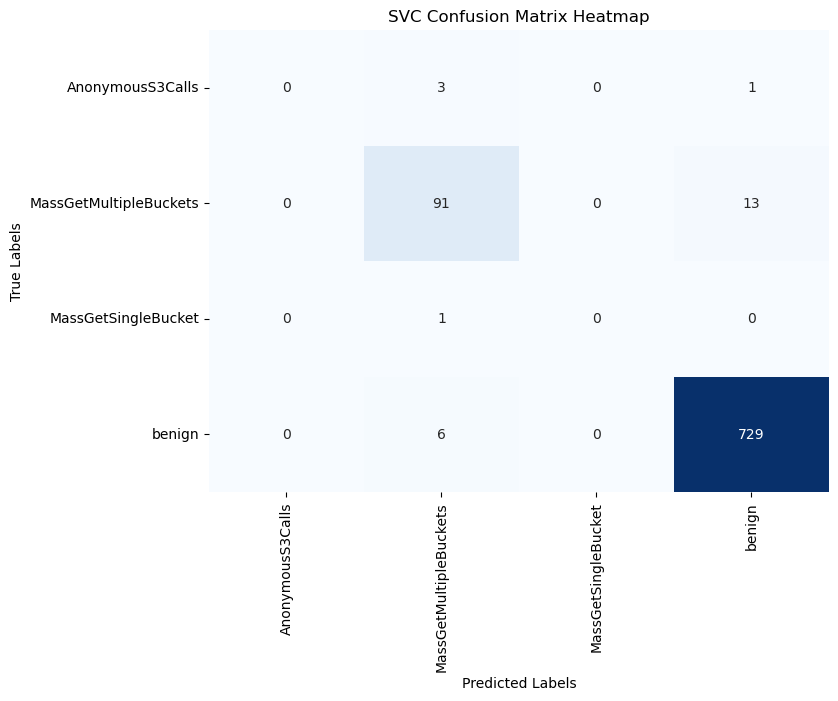

In [20]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, 
            xticklabels=['AnonymousS3Calls', 'MassGetMultipleBuckets', 'MassGetSingleBucket', 'benign'], yticklabels=['AnonymousS3Calls', 'MassGetMultipleBuckets', 'MassGetSingleBucket', 'benign'])

plt.title('SVC Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [6]:
# note that the importance can only be calculated for RandomForest
importance_df = pd.DataFrame({
    'Feature': df.columns[:-2],
    'Importance': classifier.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importance_df)

           Feature  Importance
3        eventName    0.332449
1         readOnly    0.271301
0        eventTime    0.134624
5  sourceIPAddress    0.113334
2    eventCategory    0.094403
4      eventSource    0.043051
7        errorCode    0.006918
6     errorMessage    0.003920
